# Peak models from the sequential fitting module

This notebook runs the two CCP4 peak models in `xfel_gaussian` from one YAML file, `config/peaks.yaml`.

- **Sequential fit** (`sequential_peaks_gaussian`): fit the strongest remaining local maximum, subtract that Gaussian, and repeat. The seed is that voxel, or the maximum of a spline in its neighborhood when `spline_seed` is true.

Two switches in the YAML apply to both models:

- `fix_centers`: hold each center on its seed. When false, the center is refined. In the joint fit the seed is a local maximum of the ROI. In the sequential fit it is the detected voxel, or the spline maximum when `spline_seed` is true.
- `full_covariance`: fit a rotated ellipsoid, $\Sigma=LL^\top$. When false, each Gaussian has one isotropic width.

The sequential section also sets `neighborhood_size` (odd side of the index window; 3 is $3\times 3\times 3$), `spline_seed`, and `spline_order` (3 is cubic). The example file turns the spline seed on.

Paths in the YAML are relative to the configuration file, so the notebook can be started from `notebooks/`.

In [8]:
from pathlib import Path
import importlib
from IPython.display import Image, Markdown, display
import pandas as pd
import xfel_gaussian.multi_peaks_gaussian as multi
import xfel_gaussian.sequential_peaks_gaussian as sequential
importlib.reload(multi)
importlib.reload(sequential)

config_path = Path('../config/peaks_sequential.yaml')
if not config_path.is_file():
    config_path = Path('config/peaks_sequential.yaml')
cfg = multi.load_config(config_path)

rows = []
for key, value in cfg.items():
    if str(key).startswith('_'):
        continue
    if isinstance(value, dict):
        for name, item in value.items():
            rows.append({
                'section': key,
                'parameter': name,
                'value': 'null' if item is None else item,
            })
    else:
        rows.append({
            'section': 'shared',
            'parameter': key,
            'value': 'null' if value is None else value,
        })
parameters = pd.DataFrame(rows).set_index(['section', 'parameter'])
display(Markdown(f'`{config_path.resolve()}`'))
display(parameters)

`/Users/souda/myGitHub/xfel-gaussian/config/peaks_sequential.yaml`

value
section          parameter                                                   
shared           map                      ../data/9z35_refmac3C_FoFc_OECA.mrc
sequential_peaks output_prefix       ../results/Jimin_9z35_refmac3C_FoFc_OECA
                 n_peaks                                                    5
                 threshold_sigma                                          1.0
                 fit_radius                                              1.25
                 sigma_min                                                0.1
                 sigma_max                                                2.0
                 max_shift                                                1.2
                 min_separation                                          1.25
                 save_steps                                             False
                 fix_centers                                             True
                 method                                       full_covariance
                 zero_baseline                                           True
                 neighborhood_size                                          3
                 spline_seed                                             True
                 spline_order                                               3
                 subtraction_radius                                      null
                 save_gaussians                                          True

## Sequential subtraction

`sequential.run` reads the `sequential_peaks` section of the same file. With `spline_seed: true` the seed is the maximum of a spline of order `spline_order` inside the `neighborhood_size` neighborhood of the voxel selected by `choose_peak`. With `fix_centers: true` the fitted center is that seed, so `x_A`, `y_A`, and `z_A` match the seed and can lie between voxels. `peak_before` is the residual at the detected voxel, which is the value compared with the threshold. Only the Gaussian is subtracted; the fitted background stays in the map. Both `multi.run` and `sequential.run` then write that residual density as a CCP4 map beside the input, named by inserting `_residual` before the input suffix, and again as `{prefix}_residual.map`.

,iteration,amplitude,x_A,y_A,z_A,sigma_1_A,sigma_2_A,sigma_3_A,R2,n_at_bound,center_fixed,full_covariance
0,1,2.792,11.732,10.360,11.042,1.164,1.126,1.062,0.928,0,True,True
1,2,2.541,9.034,10.986,10.793,1.140,1.035,0.910,0.904,0,True,True
2,3,2.310,10.812,8.218,9.123,1.284,0.975,0.939,0.878,0,True,True
3,4,1.926,9.993,8.156,6.363,1.191,1.041,0.901,0.989,0,True,True
4,5,1.444,11.032,11.803,8.151,0.994,0.944,0.859,0.821,0,True,True


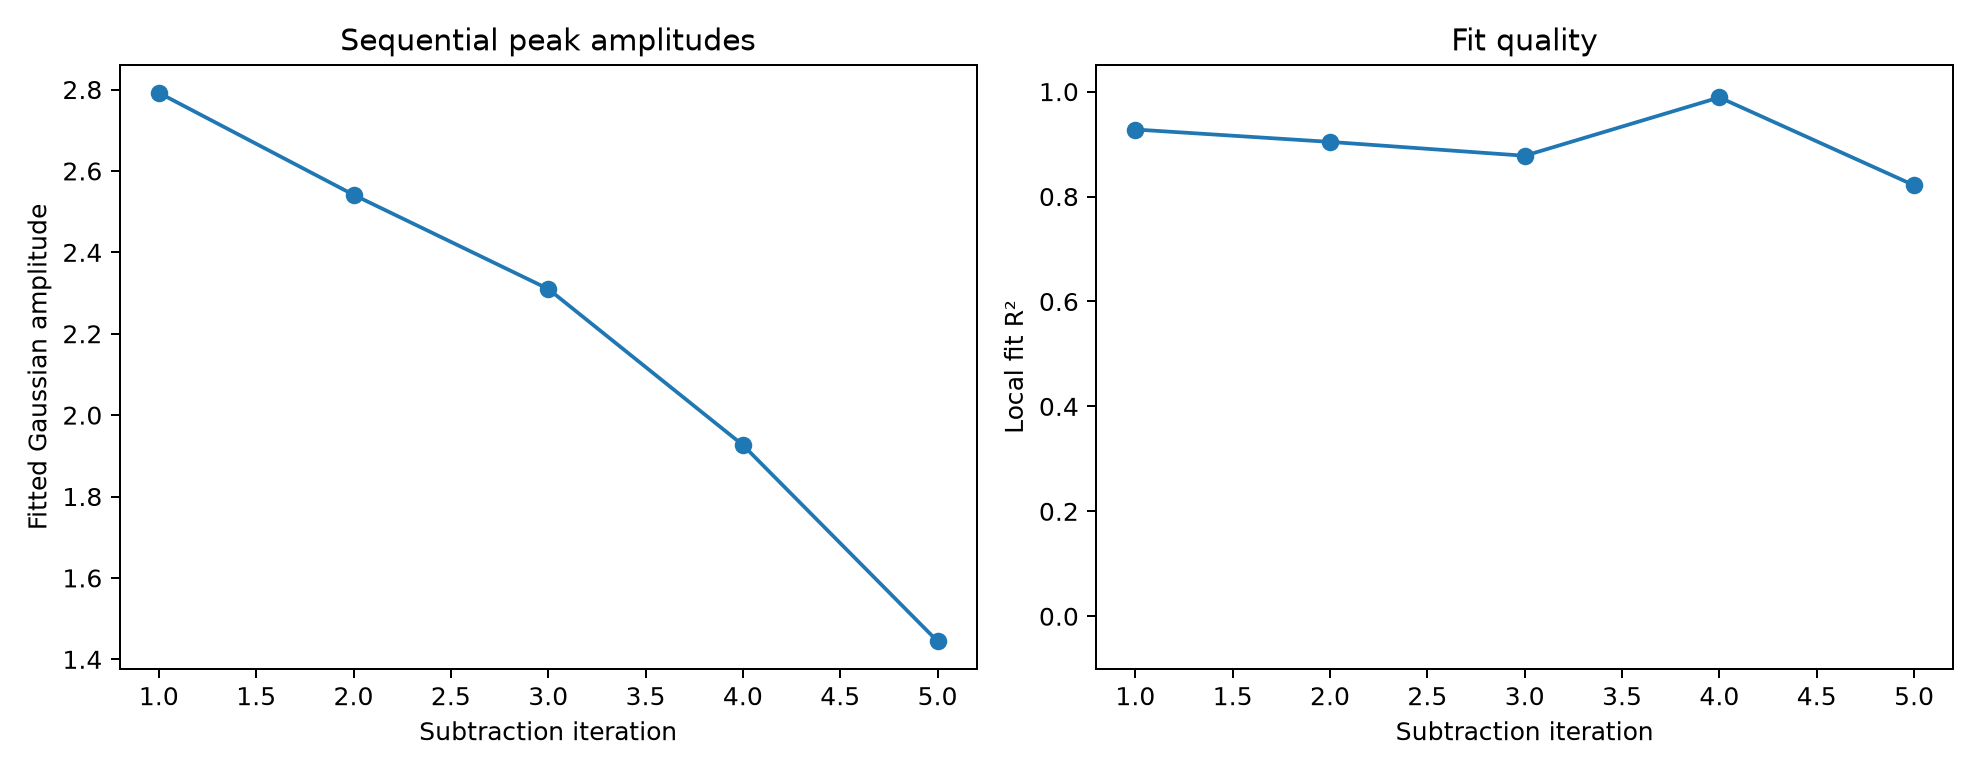

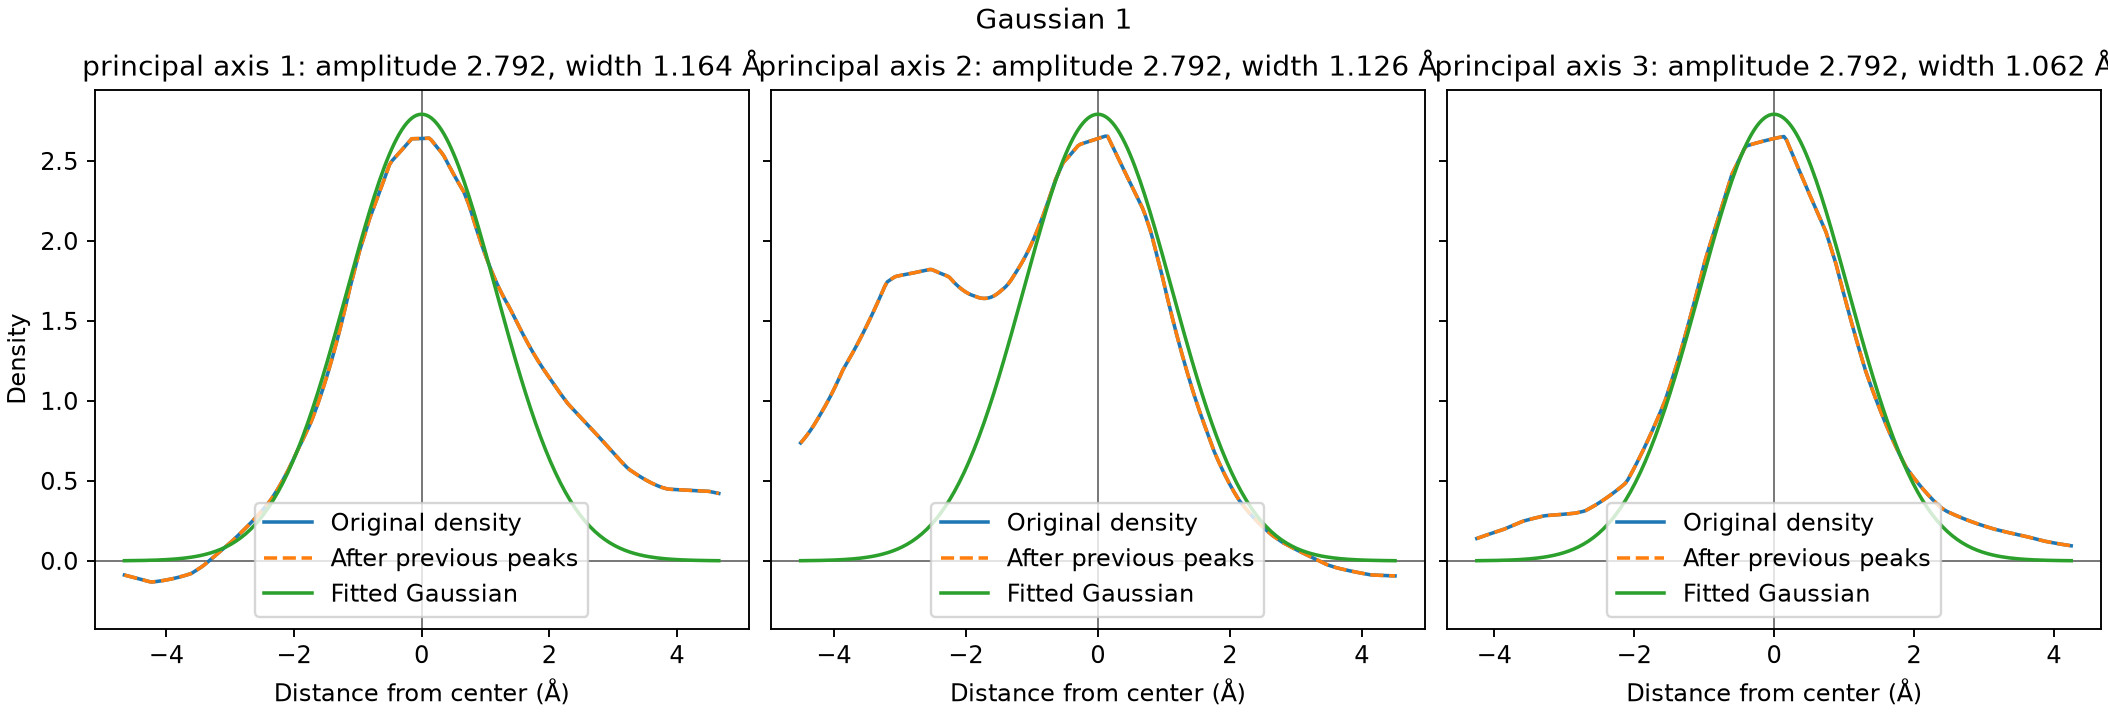

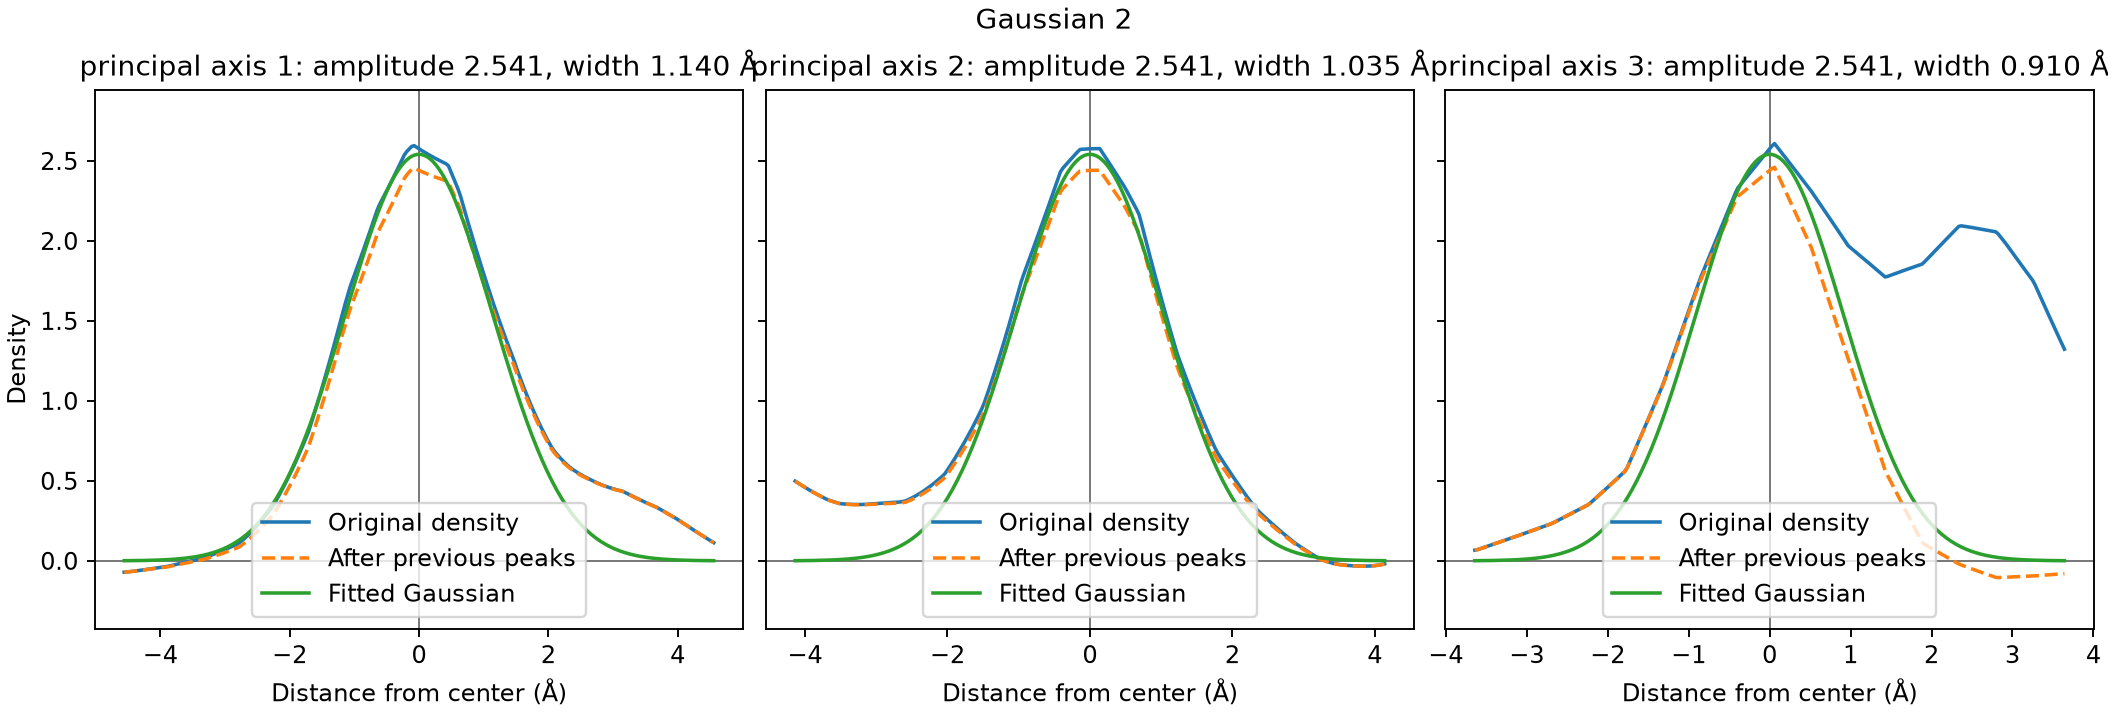

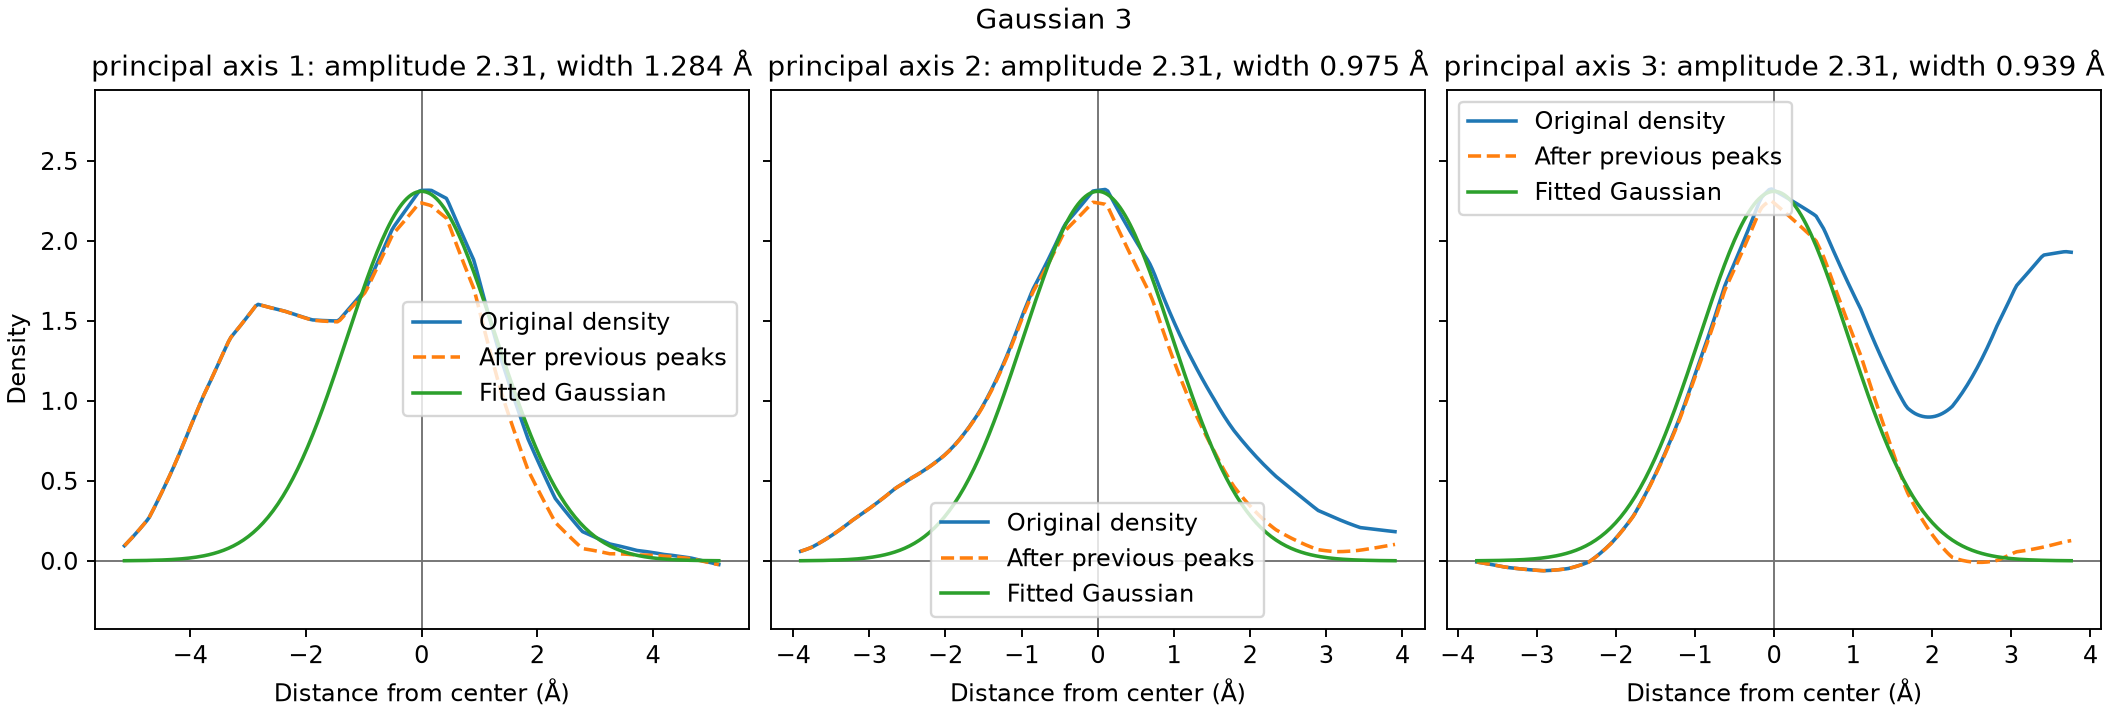

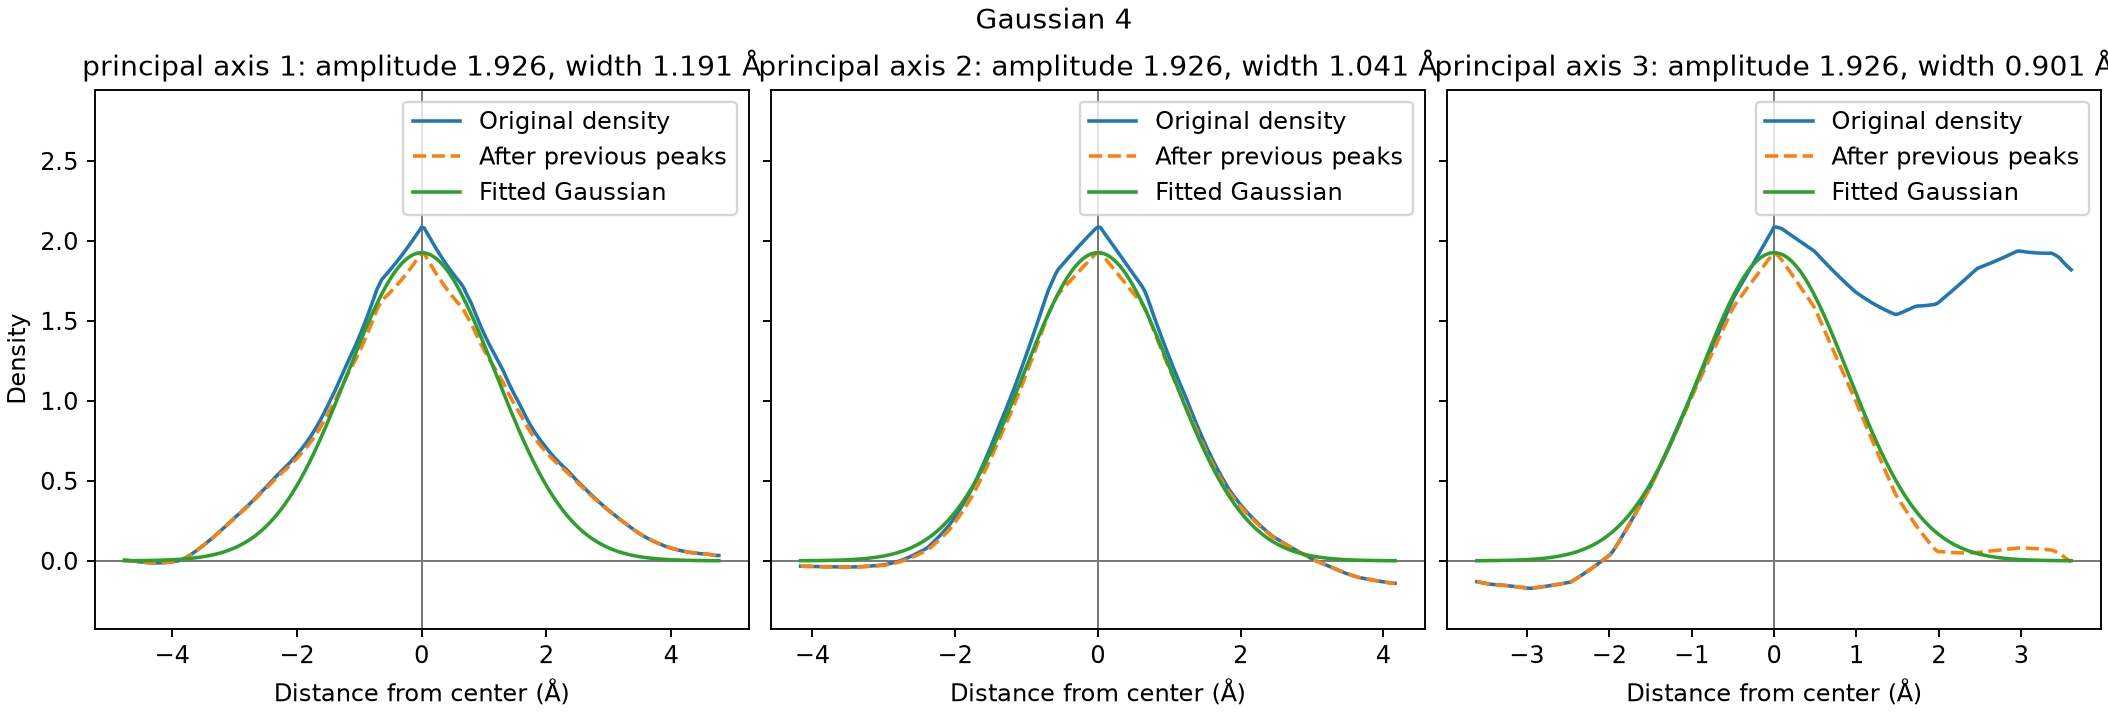

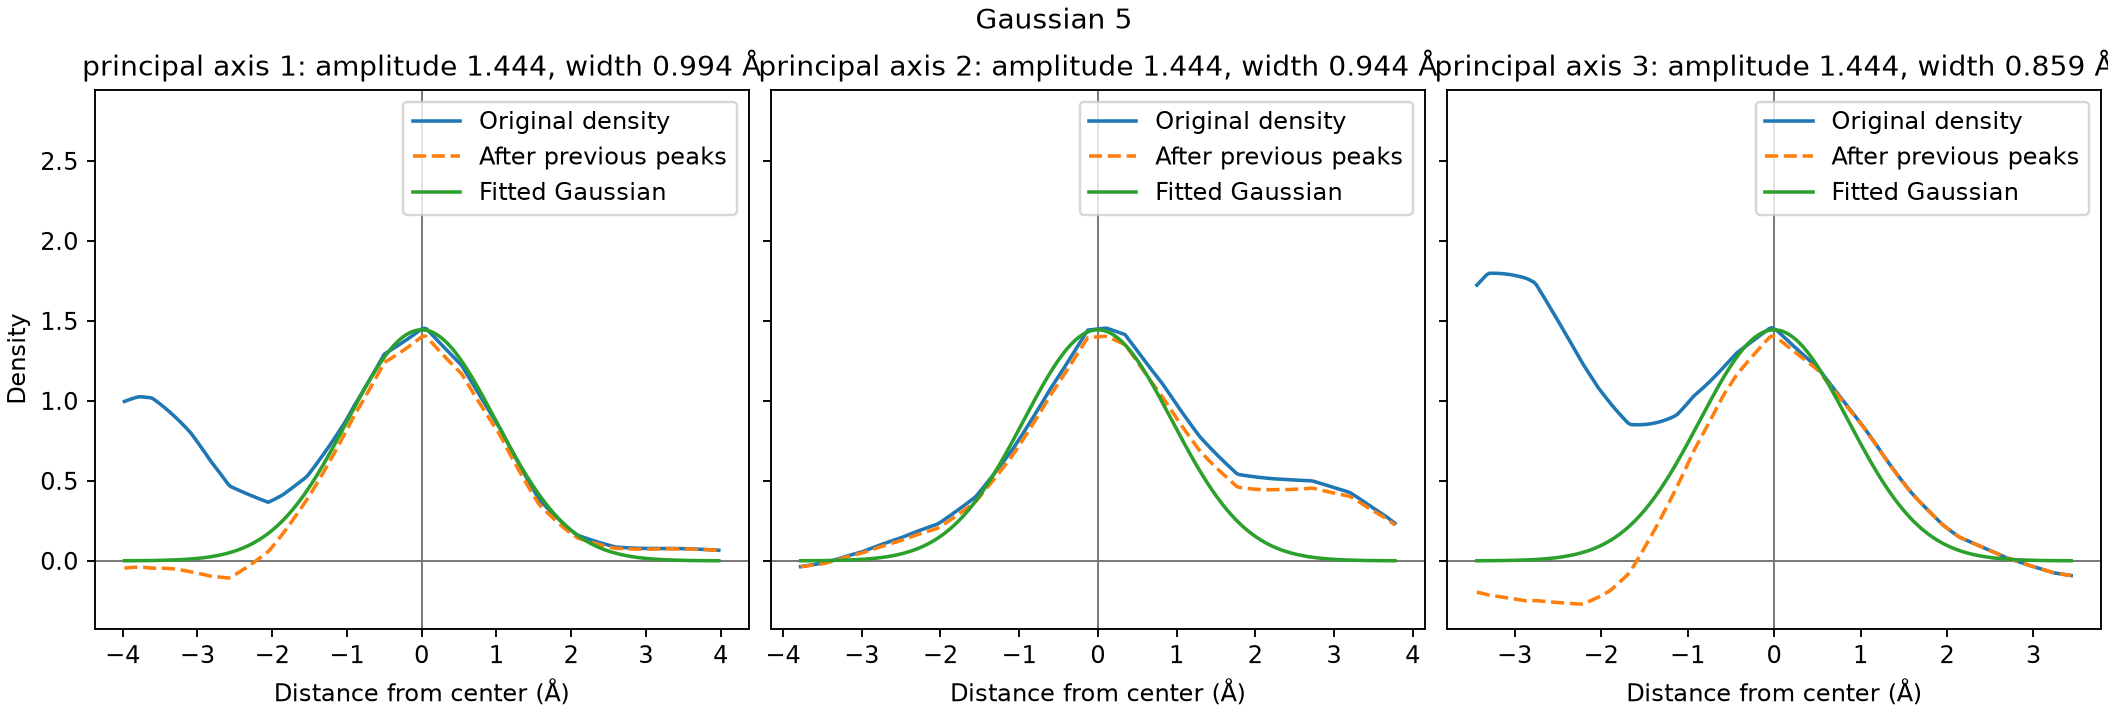

Centers: /Users/souda/myGitHub/xfel-gaussian/results/Jimin_9z35_refmac3C_FoFc_OECA_centers.csv
Centers PDB: /Users/souda/myGitHub/xfel-gaussian/results/Jimin_9z35_refmac3C_FoFc_OECA_centers.pdb
Residual map: /Users/souda/myGitHub/xfel-gaussian/data/9z35_refmac3C_FoFc_OECA_residual.mrc


In [9]:
history = sequential.run(cfg, verbose=False)
if len(history):
    display(history[[
        'iteration', 'amplitude', 'x_A', 'y_A', 'z_A',
        'sigma_1_A', 'sigma_2_A', 'sigma_3_A', 'R2', 'n_at_bound',
        'center_fixed', 'full_covariance',
    ]].round(3))
else:
    print('No peaks were accepted.')

diagnostics = history.attrs.get('diagnostics')
if diagnostics and Path(diagnostics).is_file():
    display(Image(filename=diagnostics))

for profile in history.attrs.get('profile_plots', []):
    if Path(profile).is_file():
        display(Image(filename=profile))

print('Centers:', history.attrs.get('centers_csv'))
print('Centers PDB:', history.attrs.get('centers_pdb'))
print('Residual map:', history.attrs.get('residual_map'))

## Sections through each subtracted ellipsoid

Each figure uses the same layout for one sequential peak. The density images show the current map: the original density after every previously accepted Gaussian has been removed. That is the map the new peak is fitted to. The first peak is the original map, because nothing has been subtracted yet. Removal matches the fit: only the Gaussian, and only inside a sphere of radius five times that peak's longest principal width. The local background stays in the map. The model is this peak's Gaussian plus the local background fitted with it. The curves are the $1\sigma$ and $2\sigma$ sections of that ellipsoid.

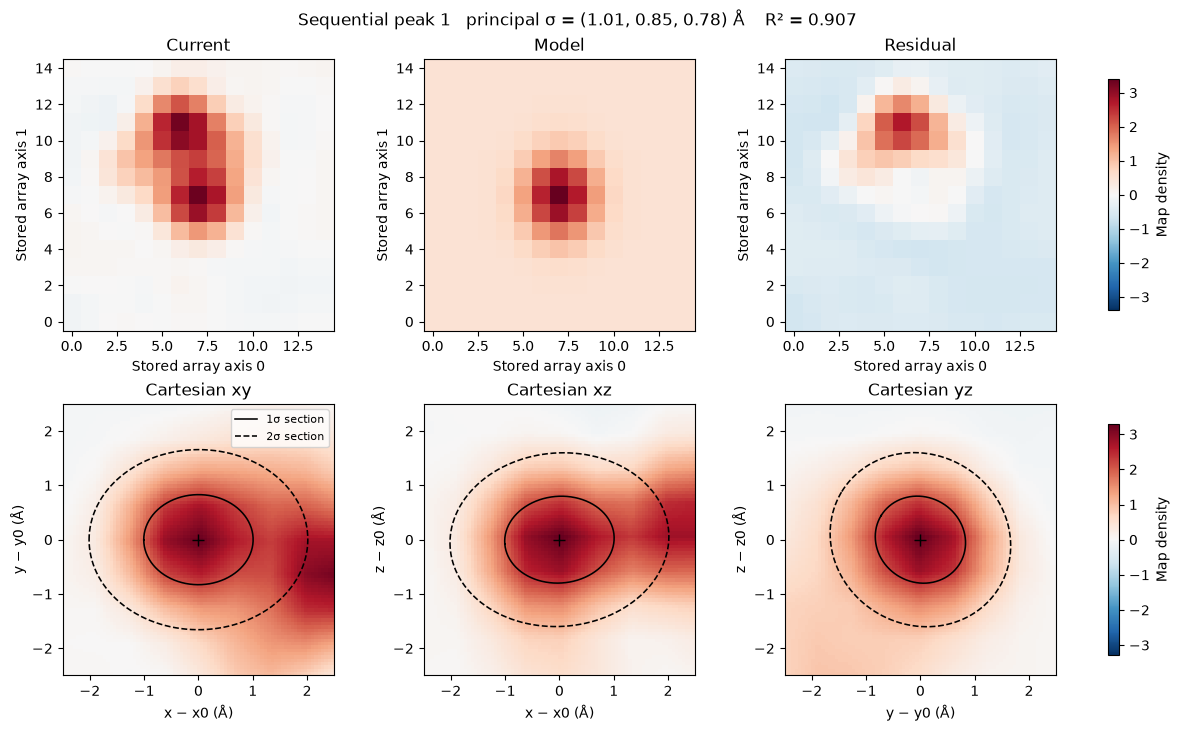

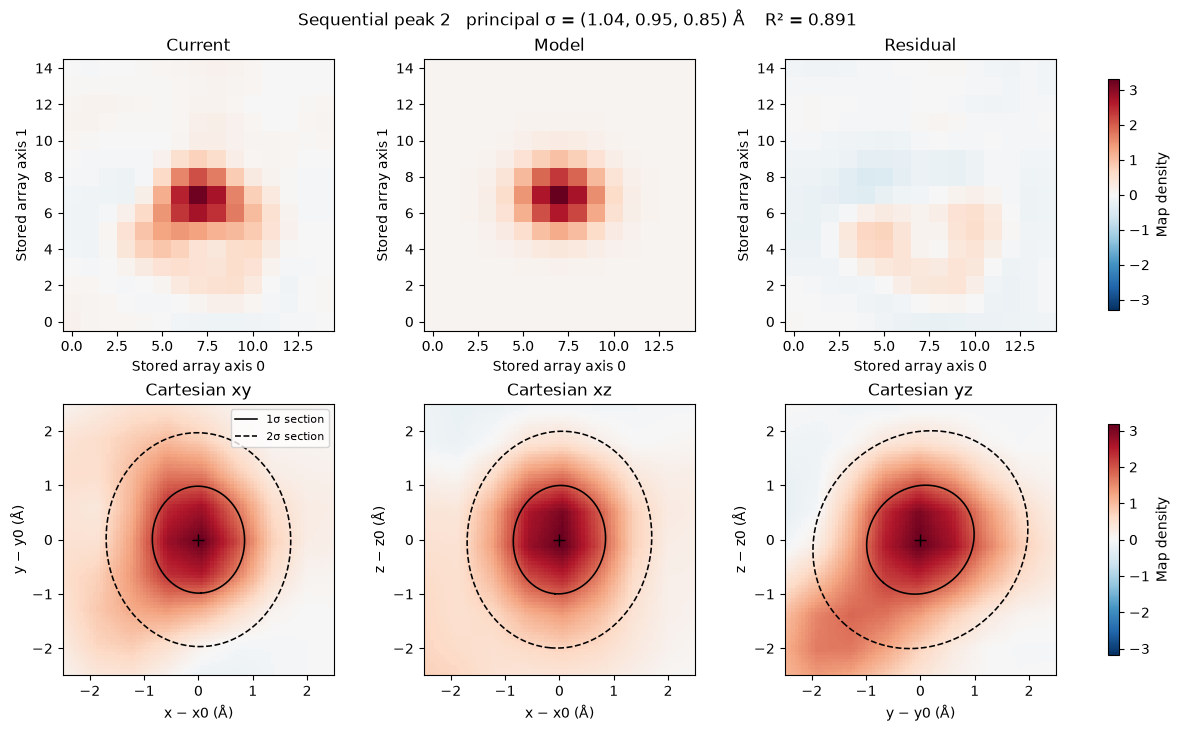

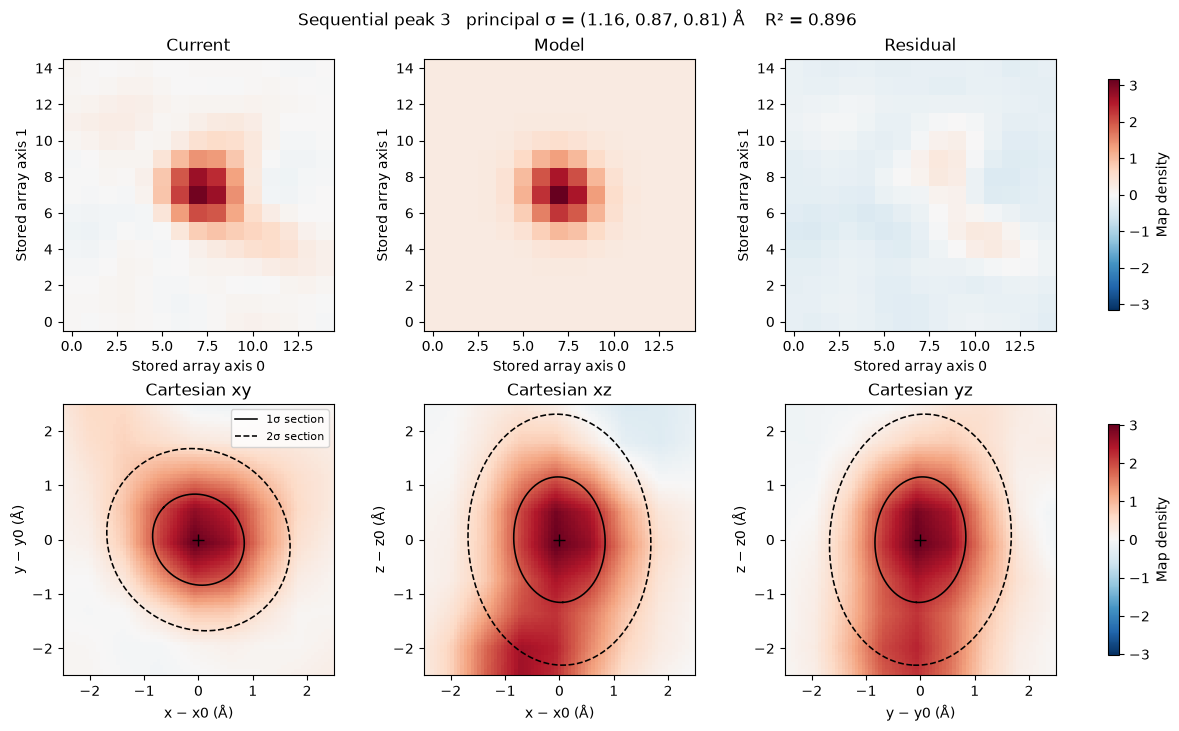

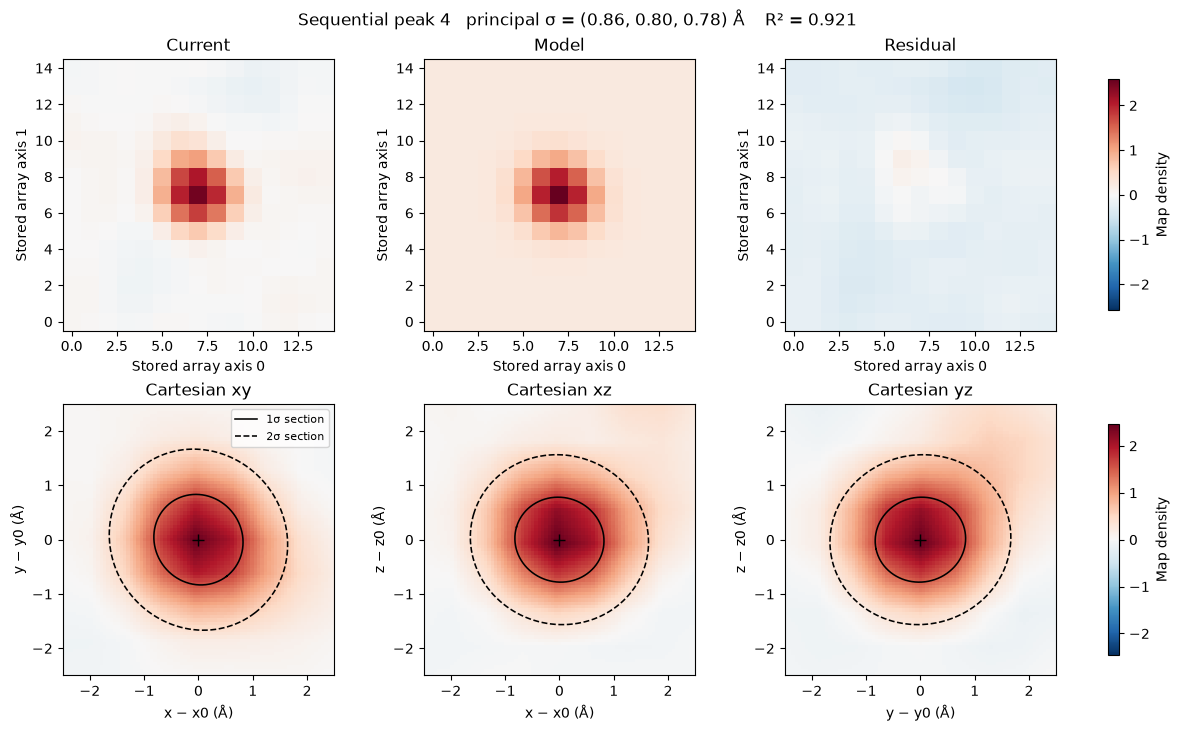

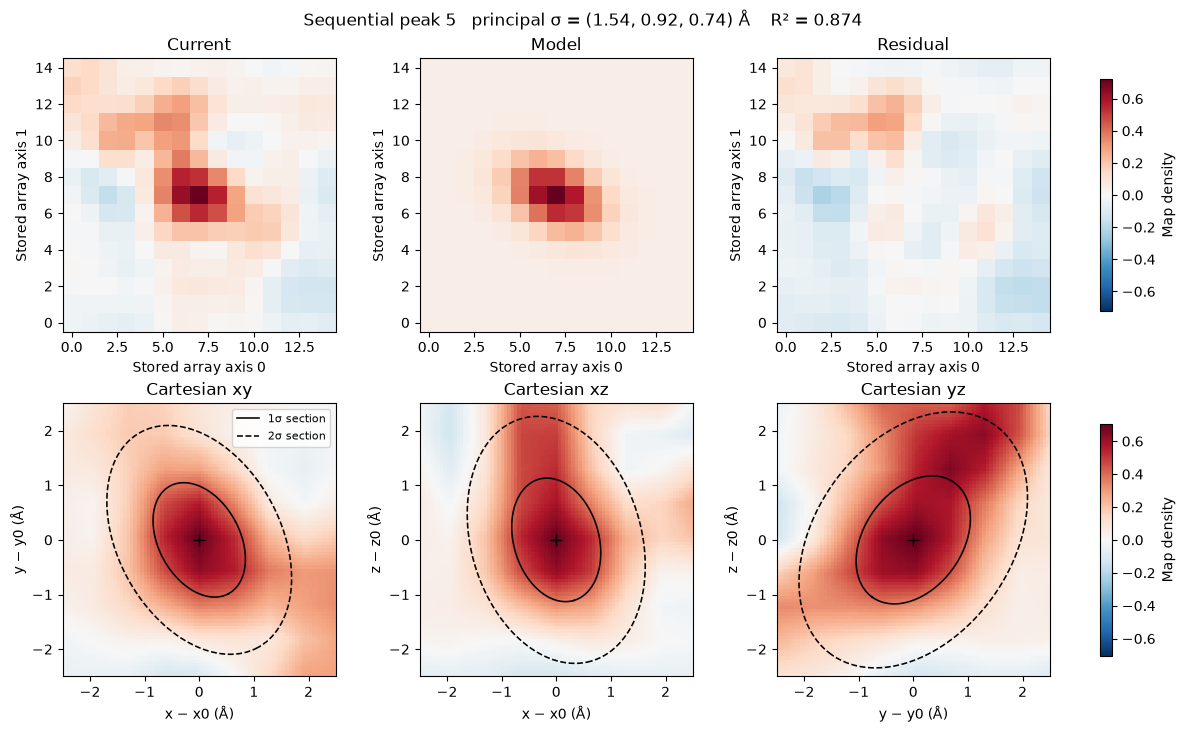

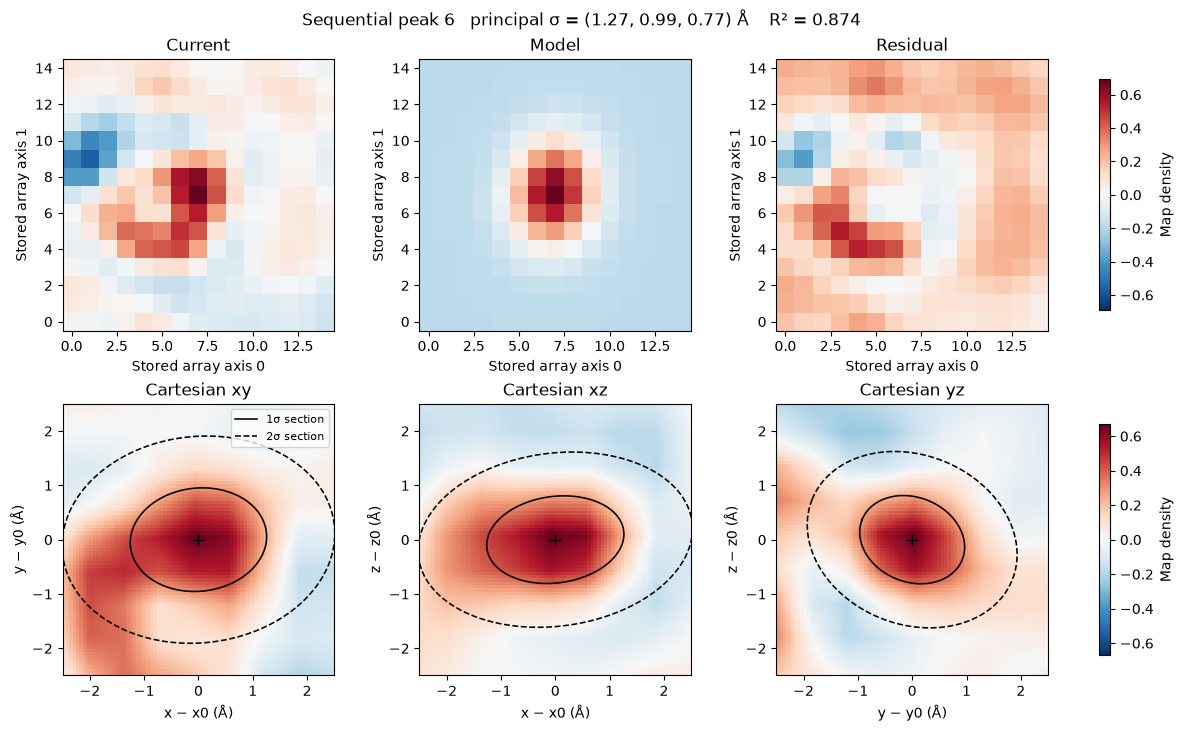

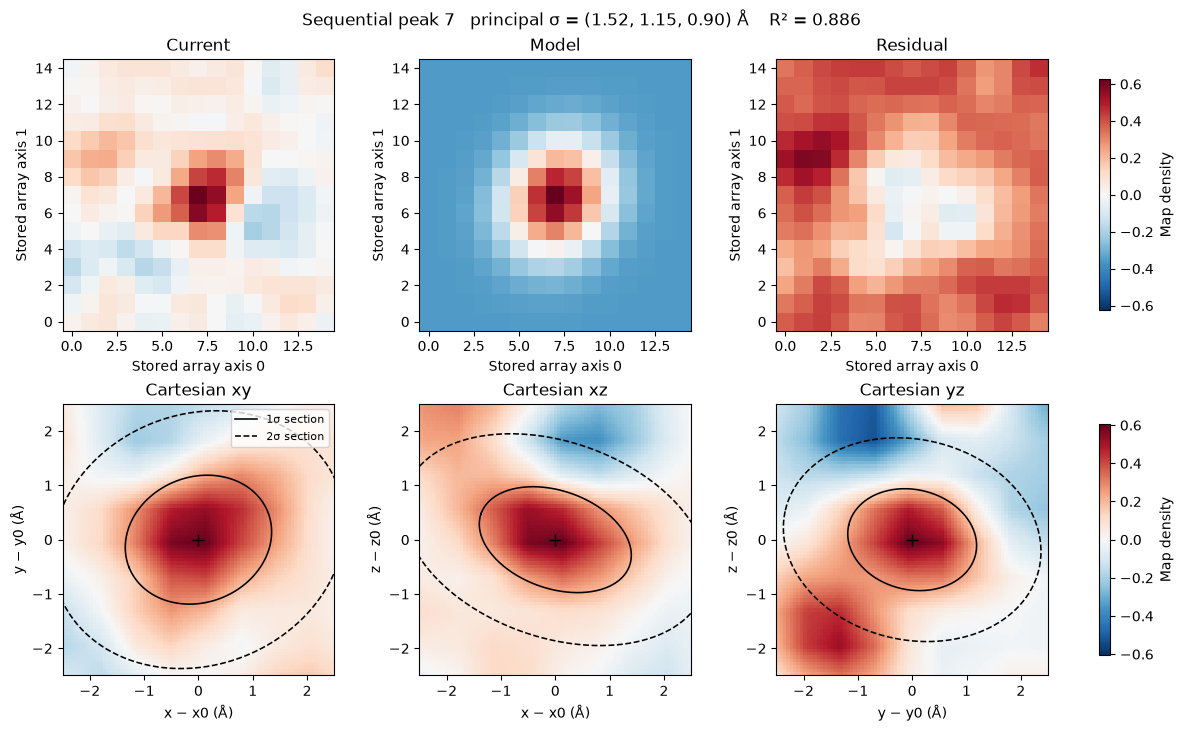

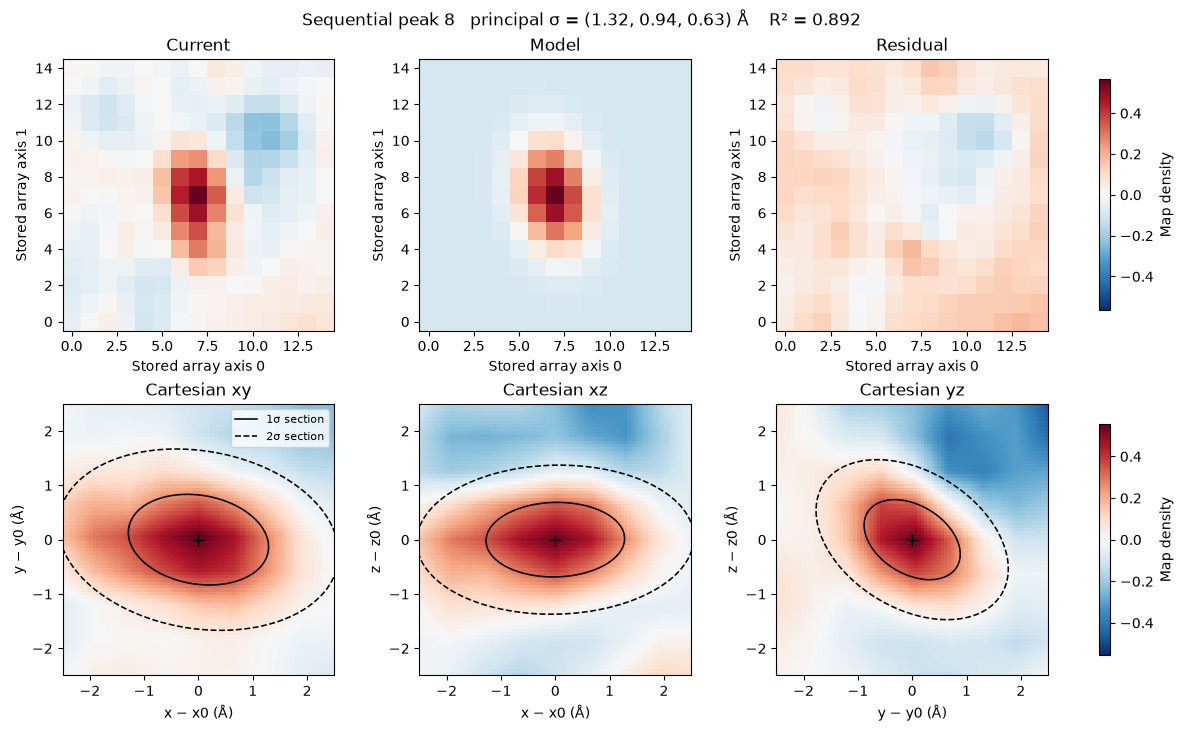

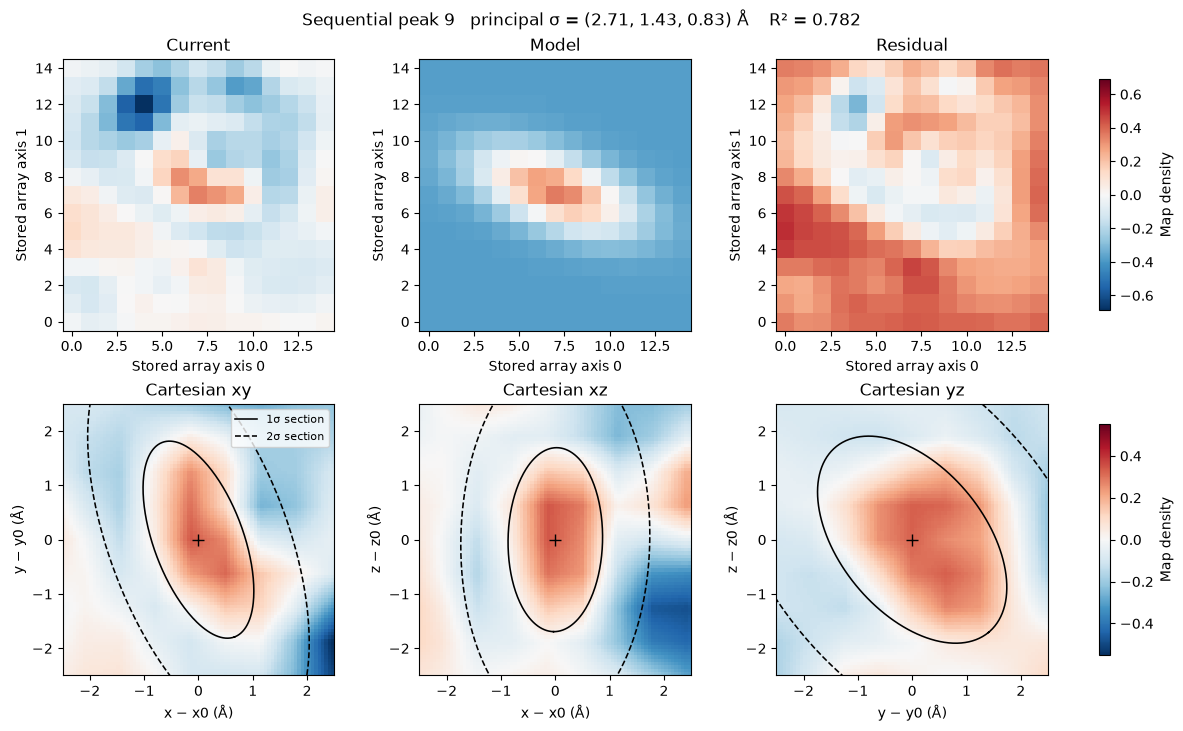

In [23]:
if len(history) == 0:
    print('No peaks were accepted.')
else:
    current = np.array(rho, dtype=float, copy=True)
    for _, row in history.iterrows():
        plot_ellipsoid_section(
            row,
            lambda points, peak=row: float(peak.background) + gaussian_values(points, peak),
            title=(
                f'Sequential peak {int(row.iteration)}   '
                f'principal σ = ({row.sigma_1_A:.2f}, {row.sigma_2_A:.2f}, {row.sigma_3_A:.2f}) Å'
                f'    R² = {row.R2:.3f}'
            ),
            values=current,
            density_label='Current',
        )
        subtract_fitted_gaussian(current, row)